# Introduction to Tree Methods

Imagine I play tennis every saturday and I always invite a friend to come with me. 
Sometimes my friend shows up, sometimes not.
For him it depends on a variety of factors, such as: weather, temperature, humidity, wind...
I start keeping track of these features and whether or not he showed up to play with me. 
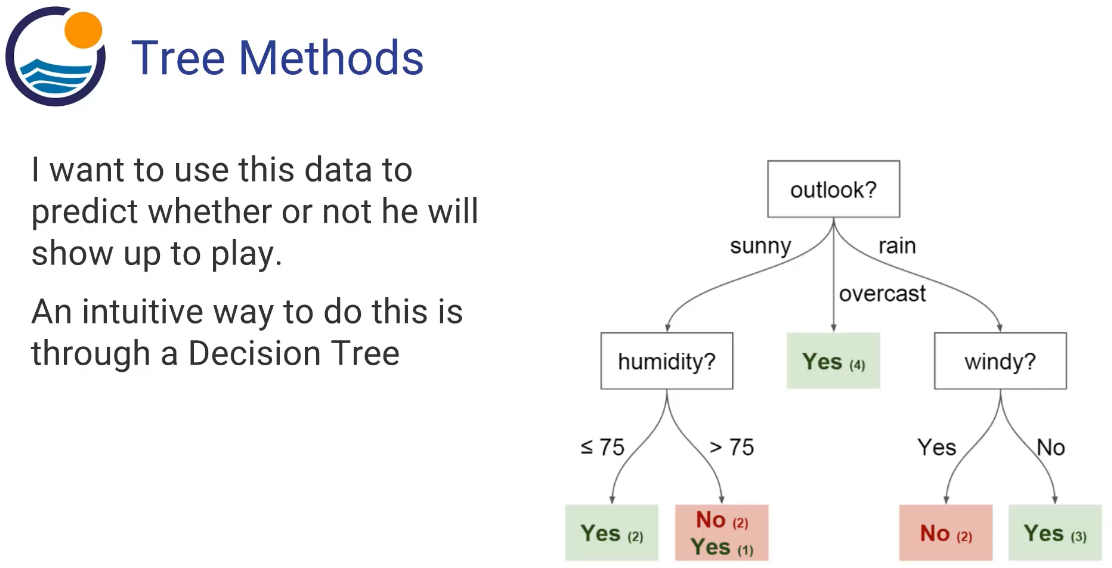

In this tree we have:
- Nodes: Split for the value of a certain attribute
- Edges: Outcome of a split to next node
- Root: The node that performs the first split
- Leaves: Terminal nodes that predict the outcome
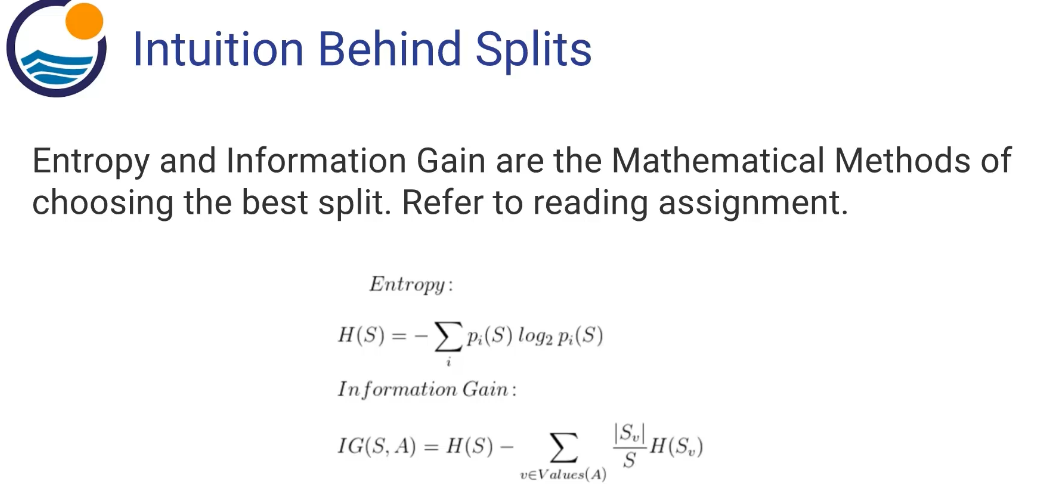
--> actual feature is to choose the best split that predicts the data

# Random Forest
To improve performance, we can use many trees with a random sample of reatures chosen as the split
- A new random sample of features is chosen for **every single tree at every single split**
- For **classification**, m is typically chosen to be the square root of p. (where p is the full set of features)
What's the point?
- suppose there is **one very strong feature** in the dataset. When using "bagged" trees, most of the trees will use that feature as the top split, resulting in a group of similar trees that are **highly correlated**
- Averaging highly correlated quantities does not significantly reduce variance.
- By randomly leaving out candidate features from each split, Random Forest **decorrelate** the trees, such that the averaging process can reduce the variance of the resulting model. 

In [3]:
import pandas as pd
import numpy as np

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [5]:
df = pd.read_csv('Refactored_Py_DS_ML_Bootcamp-master 2/15-Decision-Trees-and-Random-Forests/kyphosis.csv')

In [6]:
df

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15
...,...,...,...,...
76,present,157,3,13
77,absent,26,7,13
78,absent,120,2,13
79,present,42,7,6


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Kyphosis  81 non-null     object
 1   Age       81 non-null     int64 
 2   Number    81 non-null     int64 
 3   Start     81 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 2.7+ KB


In [8]:
df.describe()

,Age,Number,Start
count,81.000000,81.000000,81.000000
mean,83.654321,4.049383,11.493827
std,58.104251,1.619423,4.883962
min,1.000000,2.000000,1.000000
25%,26.000000,3.000000,9.000000
50%,87.000000,4.000000,13.000000
75%,130.000000,5.000000,16.000000
max,206.000000,10.000000,18.000000


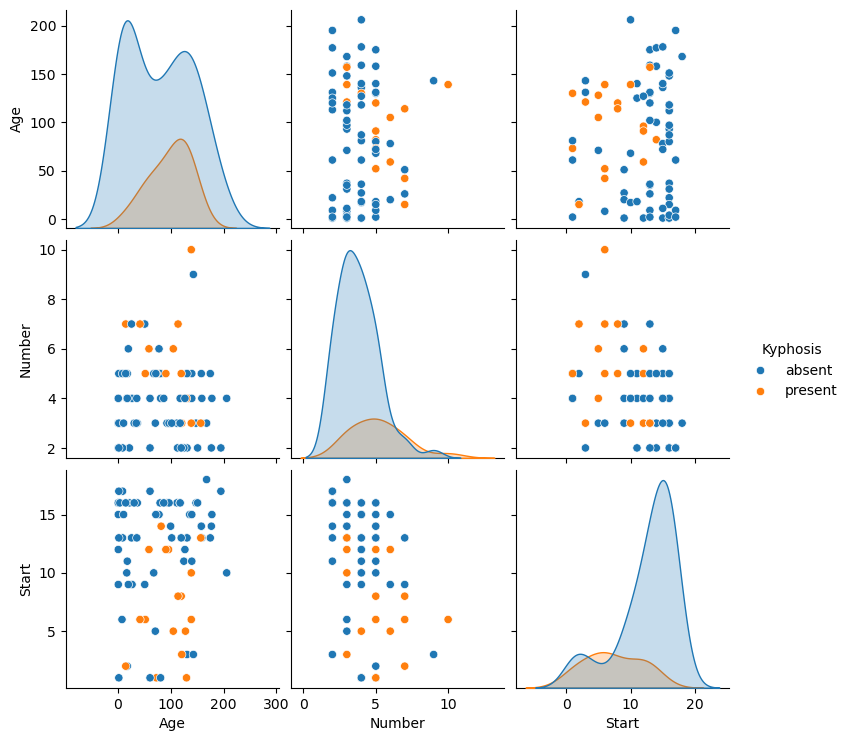

In [9]:
sns.pairplot(df, hue='Kyphosis')
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X=df.drop('Kyphosis', axis = 1)

In [12]:
y = df['Kyphosis']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

In [14]:
# import decision tree
from sklearn.tree import DecisionTreeClassifier

In [15]:
dtree = DecisionTreeClassifier()

In [16]:
dtree.fit(X_train, y_train)

DecisionTreeClassifier()

In [17]:
predictions = dtree.predict(X_test)

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

In [19]:
print(confusion_matrix(y_test, predictions))
print('\n')
print(classification_report(y_test, predictions))

[[18  4]
 [ 1  2]]


              precision    recall  f1-score   support

      absent       0.95      0.82      0.88        22
     present       0.33      0.67      0.44         3

    accuracy                           0.80        25
   macro avg       0.64      0.74      0.66        25
weighted avg       0.87      0.80      0.83        25



In [20]:
# let's compare with random forest model
from sklearn.ensemble import RandomForestClassifier

In [21]:
rfc = RandomForestClassifier(n_estimators = 200)

In [22]:
rfc.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200)

In [23]:
rfc_pred = rfc.predict(X_test)

In [24]:
print(confusion_matrix(y_test, rfc_pred))
print('\n')
print(classification_report(y_test, rfc_pred))

[[20  2]
 [ 2  1]]


              precision    recall  f1-score   support

      absent       0.91      0.91      0.91        22
     present       0.33      0.33      0.33         3

    accuracy                           0.84        25
   macro avg       0.62      0.62      0.62        25
weighted avg       0.84      0.84      0.84        25



In [25]:
df['Kyphosis'].value_counts()

Kyphosis
absent     64
present    17
Name: count, dtype: int64

### First thing to do sometimes for a DS is to run a Random Forest example to see the correlation